In [1]:
# Import dependencies 
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Set working directory to MASE6401/
# Refer back to your specific set up
current_dir = os.getcwd()   
#current_dir = r""
project_root = os.path.dirname(current_dir)  

# Set path variables
data_dir = os.path.join(project_root, 'data')                   
mts_metals_dir = os.path.join(data_dir, 'MTS_metals')
mts_sg_dir = os.path.join(data_dir, 'MTS_SG')
results_dir = os.path.join(project_root, 'results')

print(f"Data directory: {data_dir}")
print(f"MTS Metals directory: {mts_metals_dir}")
print(f"Results directory: {results_dir}")

# Load excel file paths and example data to a dataframe object
test_files = os.listdir(mts_metals_dir)
file_path = os.path.join(mts_metals_dir, test_files[0])

metadata = pd.read_excel(file_path, sheet_name="Sheet1", header = 0)
data = pd.read_excel(file_path, sheet_name="Sheet2", header = 1)

print(f"\n Data Loaded from :{file_path}")

Data directory: d:\tensile-analysis-Ecazares\data
MTS Metals directory: d:\tensile-analysis-Ecazares\data\MTS_metals
Results directory: d:\tensile-analysis-Ecazares\results

 Data Loaded from :d:\tensile-analysis-Ecazares\data\MTS_metals\4_Al_Data_Corrupted.xlsx


## 5 - Materials Science Specific Operations

Now we'll transform raw testing data into meaningful mechanical properties. 

### Understanding Our Raw Data

Recall what the MTS machine measures:
- **Load (N)**: Force from load cell
- **Crosshead (mm)**: Machine displacement
- **Extensometer (mm)**: Specimen deformation

To get mechanical properties, we need:
- **Stress ($\sigma$)**: Load / Cross-sectional Area
- **Strain ($\varepsilon$)**: Deformation / Original Length

In [2]:
# Explore metadata info (Sheet 1)
metadata.head()

,Variable,Width (mm),Final Width (mm),Thickness (mm),Final Thickness (mm),Initial Marked Gage Length (mm),Area (mm²),Final Area (mm²),Maximum Force (N),Maximum Stress (N/mm²),Elongation at Fracture (%),Elongation after Break (%),Modulus of Elasticity (N/mm²),Yield Strength (Offset = 0.2%) (N/mm²),Ultimate Tensile Strength (N/mm²),Reduction of Area (%),Final Marked Gage Length (mm)
0,Value,13.72,10.32,3.2,2.73,50,43.904,28.1736,16661.588,379.5,28.951,30.74,176173.677,229.473,379.5,35.8291,65.37


In [3]:
# Explore test data info (Sheet 2)
data.head()

,Index,Load (N),Crosshead (mm),Extensometer (mm),Time (sec)
0,0,-1.322186,-0.000047,0.000118,no
1,1,-0.838275,-0.000047,0.000239,date
2,2,-0.278150,-0.000047,0.000199,here
3,3,-0.392628,-0.000047,0.000026,2.062
4,4,-1.146567,-0.000047,0.000282,2.102


### 5.1 Defining Specimen Geometry

For a standard tensile specimen, we need to know:
- Cross-sectional area (for stress calculation)
- Gauge length (for strain calculation)

In [4]:
# Specimen geometry (set hardcoded values) 
width_mm = 13.52
thickness_mm = 3.16
gauge_length_mm = 50

area_mm2 = width_mm * thickness_mm

print(f"Gauge Length: {gauge_length_mm} mm")
print(f"Cross-sectional Area: {area_mm2:.4f} mm²")

Gauge Length: 50 mm
Cross-sectional Area: 42.7232 mm²


### Practice 5.1 Extracting Metadata Values

- Extract the column value for the specific metadata value using the DataFrame `metadata`

**Note**: Remember the `.columns` method

In [5]:
# Extract column names 
metadata.columns

Index(['Variable', 'Width (mm)', 'Final Width (mm)', 'Thickness (mm)',
       'Final Thickness (mm)', 'Initial Marked Gage Length (mm)', 'Area (mm²)',
       'Final Area (mm²)', 'Maximum Force (N)', 'Maximum Stress (N/mm²)',
       'Elongation at Fracture (%)', 'Elongation after Break (%)',
       'Modulus of Elasticity (N/mm²)',
       'Yield Strength (Offset = 0.2%) (N/mm²)',
       'Ultimate Tensile Strength (N/mm²)', 'Reduction of Area (%)',
       'Final Marked Gage Length (mm)'],
      dtype='object')

In [6]:
# Specimen geometry (extract from loaded metadata)
width_mm = metadata["Width (mm)"][0]
thickness_mm = metadata["Thickness (mm)"][0]
gauge_length_mm = metadata["Initial Marked Gage Length (mm)"][0]

area_mm2 = width_mm * thickness_mm

print(f"Gauge Length: {gauge_length_mm} mm")
print(f"Cross-sectional Area: {area_mm2:.4f} mm²")

Gauge Length: 50 mm
Cross-sectional Area: 43.9040 mm²


### 5.2 Calculating Engineering Stress

In [7]:
data.head()

,Index,Load (N),Crosshead (mm),Extensometer (mm),Time (sec)
0,0,-1.322186,-0.000047,0.000118,no
1,1,-0.838275,-0.000047,0.000239,date
2,2,-0.278150,-0.000047,0.000199,here
3,3,-0.392628,-0.000047,0.000026,2.062
4,4,-1.146567,-0.000047,0.000282,2.102


In [8]:
# Create a new column for stress
data['Stress (MPa)'] = data['Load (N)'] / area_mm2        # Setting df["new column"] = values -> adds a new column to the current dataframe object.

print(f"\nFirst 5 stress values:")
print(data[['Load (N)', 'Stress (MPa)']].head())

# Now using the .max() method returns the value for the UTS in the new added column
print(f"\nMaximum stress (UTS): {data['Stress (MPa)'].max():.2f} MPa")   


First 5 stress values:
   Load (N)  Stress (MPa)
0 -1.322186     -0.030115
1 -0.838275     -0.019093
2 -0.278150     -0.006335
3 -0.392628     -0.008943
4 -1.146567     -0.026115

Maximum stress (UTS): 379.50 MPa


### 5.3 Calculating Engineering Strain

In [9]:
# Create a new column for strain (dimensionless)
data['Strain'] = data['Extensometer (mm)'] / gauge_length_mm

# Also create strain in percentage for easier interpretation
data['Strain (%)'] = data['Strain'] * 100

print(f"\nFirst 5 strain values:")
print(data[['Extensometer (mm)', 'Strain', 'Strain (%)']].head())

print(f"\nMaximum strain: {data['Strain'].max():.4f} ({data['Strain (%)'].max():.2f}%)")


First 5 strain values:
   Extensometer (mm)        Strain  Strain (%)
0           0.000118  2.351487e-06    0.000235
1           0.000239  4.782066e-06    0.000478
2           0.000199  3.984330e-06    0.000398
3           0.000026  5.149649e-07    0.000051
4           0.000282  5.633918e-06    0.000563

Maximum strain: 0.5410 (54.10%)


In [10]:
data.head()

,Index,Load (N),Crosshead (mm),Extensometer (mm),Time (sec),Stress (MPa),Strain,Strain (%)
0,0,-1.322186,-0.000047,0.000118,no,-0.030115,2.351487e-06,0.000235
1,1,-0.838275,-0.000047,0.000239,date,-0.019093,4.782066e-06,0.000478
2,2,-0.278150,-0.000047,0.000199,here,-0.006335,3.984330e-06,0.000398
3,3,-0.392628,-0.000047,0.000026,2.062,-0.008943,5.149649e-07,0.000051
4,4,-1.146567,-0.000047,0.000282,2.102,-0.026115,5.633918e-06,0.000563


### 5.4 Data Cleaning: Removing Preload Data

Tensile tests typically start with a preload phase (negative or near-zero loads) for 
alignment. We should remove this for property calculations.

**Common criteria:**
- Remove data where Load < 0 (compression)
- Remove data where Load < threshold (e.g., 10 N)

In [11]:
# Check current data
print(f"Original dataset: {len(data)} points")

# Filter: Keep only positive loads above a threshold
load_threshold = 50  # N
data_clean = data[data['Load (N)'] > load_threshold].copy()

print(f"After removing preload (Load > {load_threshold} N): {len(data_clean)} points")

# Reset index for clean sequential numbering
data_clean = data_clean.reset_index(drop=True)

print("\nCleaned data first 5 rows:")
print(data_clean[['Load (N)', 'Stress (MPa)', 'Strain', 'Time (sec)']].head())

Original dataset: 3608 points
After removing preload (Load > 50 N): 3511 points

Cleaned data first 5 rows:
    Load (N)  Stress (MPa)    Strain Time (sec)
0  50.844818      1.158091  0.000009      4.942
1  53.452431      1.217484  0.000006      4.982
2  53.173195      1.211124  0.000006      5.022
3  54.900570      1.250469  0.000008      5.062
4  56.468742      1.286187  0.000009      5.102


In [12]:
data[data['Load (N)'] > load_threshold]

,Index,Load (N),Crosshead (mm),Extensometer (mm),Time (sec),Stress (MPa),Strain,Strain (%)
75,75,50.844818,0.002282,0.000438,4.942,1.158091,0.000009,0.000876
76,76,53.452431,0.002329,0.000283,4.982,1.217484,0.000006,0.000566
77,77,53.173195,0.002422,0.000302,5.022,1.211124,0.000006,0.000604
78,78,54.900570,0.002515,0.000379,5.062,1.250469,0.000008,0.000758
79,79,56.468742,0.002562,0.000465,5.102,1.286187,0.000009,0.000929
...,...,...,...,...,...,...,...,...
3602,3602,10913.351562,19.617917,18.054364,146.005005,248.573059,0.361087,36.108728
3603,3603,10666.577148,19.626440,18.090339,146.044998,242.952286,0.361807,36.180679
3604,3604,10357.694336,19.634916,18.131014,146.085007,235.916872,0.362620,36.262028
3605,3605,9987.405273,19.643439,18.176792,146.125,227.482810,0.363536,36.353584


**Note:** We use `.copy()` to create an independent DataFrame, avoiding "SettingWithCopyWarning"

### 5.5 Finding Ultimate Tensile Strength (UTS)

In [13]:
# Find maximum stress
UTS = data_clean['Stress (MPa)'].max()
UTS_index = data_clean['Stress (MPa)'].idxmax()

# Get all data at UTS point
UTS_point = data_clean.loc[UTS_index]

print(f"\nUltimate Tensile Strength: {UTS:.2f} MPa")
print(f"\nOccurred at:")
print(f"  Strain: {UTS_point['Strain']:.4f} ({UTS_point['Strain (%)']:.2f}%)")
print(f"  Time: {UTS_point['Time (sec)']:.2f} seconds")
print(f"  Load: {UTS_point['Load (N)']:.2f} N")


Ultimate Tensile Strength: 379.50 MPa

Occurred at:
  Strain: 0.1464 (14.64%)
  Time: 114.61 seconds
  Load: 16661.59 N


### 5.6 Calculating Young's Modulus (Elastic Modulus)

### 5.7 Calculating 0.2% Offset Yield Strength

### 5.8 Calculating Elongation at Failure

In [14]:
# Maximum strain represents elongation
max_strain = data_clean['Strain'].max()
elongation_percent = max_strain * 100

print(f"Elongation: {max_strain:.4f} ({elongation_percent:.2f}%)")

Elongation: 0.3650 (36.50%)


### 5.10 Creating a Summary DataFrame

Let's organize these properties in a DataFrame for easy export and comparison.

In [15]:
# Create a dictionary of properties
experiment_data = {
    # Specimen Metadata
    "Specimen Width" : width_mm, 
    "Specimen Thickness": thickness_mm,
    "Specimen Gauge Length": gauge_length_mm, 
    "Specimen Cross Section": area_mm2, 

    # Determined Properties
    "UTS": UTS, 
    "Strain at Failure": max_strain
}

# Convert to DataFrame
summary_df = pd.DataFrame([experiment_data])

In [16]:
display(summary_df)

,Specimen Width,Specimen Thickness,Specimen Gauge Length,Specimen Cross Section,UTS,Strain at Failure
0,13.72,3.2,50,43.904,379.500453,0.364999


## 6 - Data Visualization

Pandas integrates seamlessly with matplotlib for plotting. We'll create figures for our tensile test data.

### 6.1 Basic Plotting with Pandas

Pandas DataFrames have a built-in `.plot()` method that uses embedded matplotlib.

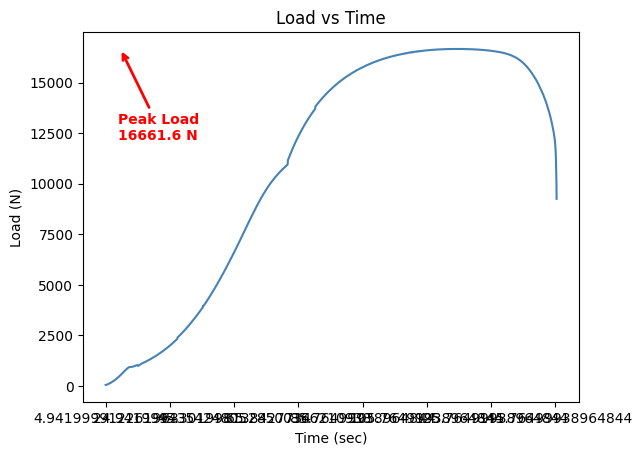

In [17]:
### Load vs Time Plot

data_clean.plot(x='Time (sec)', y='Load (N)', color='steelblue', linewidth=1.5, legend=False)
plt.title("Load vs Time")
plt.ylabel("Load (N)")

# Add annotation for max load
max_load = data_clean['Load (N)'].max()
max_load_time = data_clean.loc[data_clean['Load (N)'].idxmax(), 'Time (sec)']

plt.annotate(f'Peak Load\n{max_load:.1f} N', 
            xy=(max_load_time, max_load),
            xytext=(max_load_time - 15, max_load - 4500),
            arrowprops=dict(arrowstyle='->', color='red', lw=2),
            fontsize=10, color='red', fontweight='bold')

plt.show()

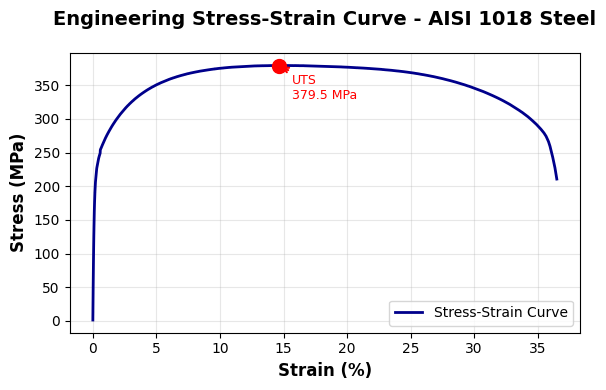

In [18]:
# Create stress-strain curve
fig, ax = plt.subplots(figsize=(6, 4))

ax.plot(data_clean['Strain'] * 100, data_clean['Stress (MPa)'], 
        color='darkblue', linewidth=2, label='Stress-Strain Curve')

ax.set_xlabel('Strain (%)', fontsize=12, fontweight='bold')
ax.set_ylabel('Stress (MPa)', fontsize=12, fontweight='bold')
ax.set_title('Engineering Stress-Strain Curve - AISI 1018 Steel', 
             fontsize=14, fontweight='bold', pad=20)
ax.grid(True, alpha=0.3)
ax.legend(loc='lower right', fontsize=10)

# Annotate key points 
UTS = data_clean['Stress (MPa)'].max()
UTS_strain = data_clean.loc[data_clean['Stress (MPa)'].idxmax(), 'Strain'] * 100

ax.plot(UTS_strain, UTS, 'ro', markersize=10, label='UTS')  # Marker Plot at (strain_UTS, UTS Value)

ax.annotate(f'UTS\n{UTS:.1f} MPa', xy=(UTS_strain, UTS),
            xytext=(UTS_strain + 1, UTS - 50),
            arrowprops=dict(arrowstyle='->', color='red', lw=1.5),
            fontsize=9, color='red')                                  # Makes the annotation 

plt.tight_layout()
plt.show()

## 7 - Data Cleaning Walktrhough

In [19]:
# Specify the corrupted data file
corrupted_file_path = os.path.join(mts_metals_dir, "4_Al_Data_Corrupted.xlsx")

# Load the metadata and data sheets into DataFrame objects
metadata_corr = pd.read_excel(corrupted_file_path, sheet_name="Sheet1", header = 0)
data_corr = pd.read_excel(corrupted_file_path, sheet_name="Sheet2", header = 1)

### 7.1 Explore Data

In [20]:
# Ensure data was loaded to the DataFrame

# 1. Check data type
print(type(data_corr))
# 2. Check the dataframe shape
print(data_corr.shape)
# 3. Check column names
print(data_corr.head())
print(data_corr.columns)
# 4. Check column dtype
print(data_corr.dtypes)

<class 'pandas.core.frame.DataFrame'>
(3608, 5)
   Index  Load (N)  Crosshead (mm)  Extensometer (mm) Time (sec)
0      0 -1.322186       -0.000047           0.000118         no
1      1 -0.838275       -0.000047           0.000239       date
2      2 -0.278150       -0.000047           0.000199       here
3      3 -0.392628       -0.000047           0.000026      2.062
4      4 -1.146567       -0.000047           0.000282      2.102
Index(['Index', 'Load (N)', 'Crosshead (mm)', 'Extensometer (mm)',
       'Time (sec)'],
      dtype='object')
Index                  int64
Load (N)             float64
Crosshead (mm)       float64
Extensometer (mm)    float64
Time (sec)            object
dtype: object


### 7.2 Extract DataFrame information

In [21]:
# 1. Print DataFrame Head
data_corr.head()

,Index,Load (N),Crosshead (mm),Extensometer (mm),Time (sec)
0,0,-1.322186,-0.000047,0.000118,no
1,1,-0.838275,-0.000047,0.000239,date
2,2,-0.278150,-0.000047,0.000199,here
3,3,-0.392628,-0.000047,0.000026,2.062
4,4,-1.146567,-0.000047,0.000282,2.102


In [22]:
# 2. Use the DataFrame metrics
data_corr.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3608 entries, 0 to 3607
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Index              3608 non-null   int64  
 1   Load (N)           3608 non-null   float64
 2   Crosshead (mm)     3608 non-null   float64
 3   Extensometer (mm)  3595 non-null   float64
 4   Time (sec)         3608 non-null   object 
dtypes: float64(3), int64(1), object(1)
memory usage: 141.1+ KB


In [23]:
data_corr.describe()

,Index,Load (N),Crosshead (mm),Extensometer (mm)
count,3608.000000,3608.000000,3608.000000,3595.000000
mean,1803.500000,10703.884494,6.508631,3.882330
std,1041.684213,6288.354484,6.387778,4.858996
min,0.000000,-13804.770508,-0.000047,-0.000251
25%,901.750000,4369.906006,0.577256,0.028941
50%,1803.500000,13828.018066,4.390134,1.615875
75%,2705.250000,16338.044434,12.024645,6.555136
max,3607.000000,16661.587891,19.661790,27.050115


In [24]:
# 3. Find NAs, Nulls or any empty cells
data_corr.isna().sum()

Index                 0
Load (N)              0
Crosshead (mm)        0
Extensometer (mm)    13
Time (sec)            0
dtype: int64

### 7.3 Plot Raw Data

<Axes: xlabel='Extensometer (mm)'>

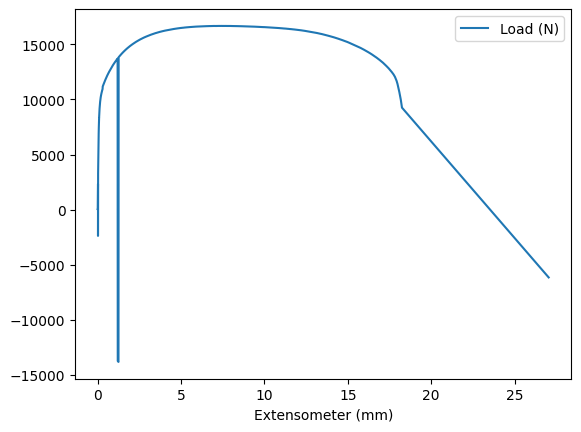

In [25]:
# Plot Load vs Extensometer
data_corr.plot("Extensometer (mm)", "Load (N)")

<Axes: xlabel='Time (sec)'>

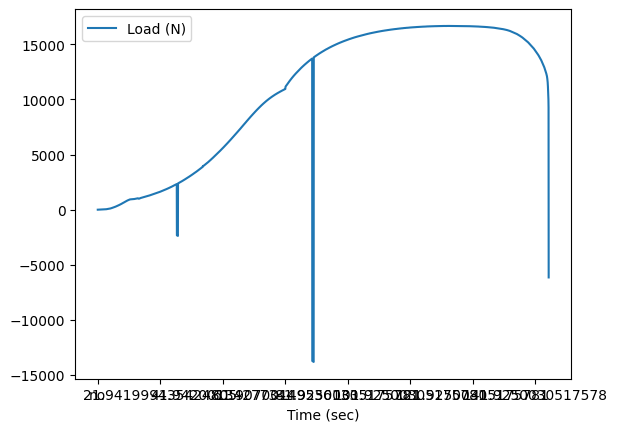

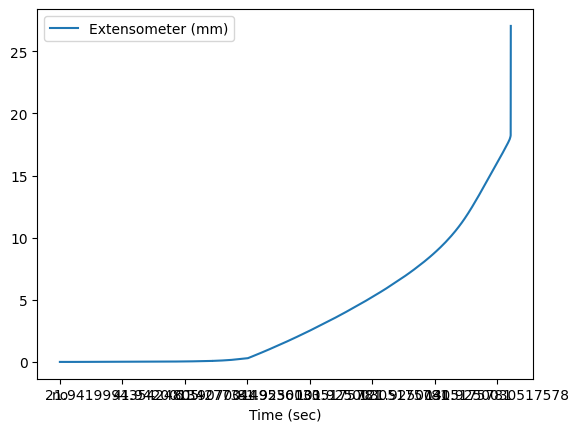

In [26]:
# Plot Time vs Load
data_corr.plot("Time (sec)", "Load (N)")
# Plot Time vs Extensometer 
data_corr.plot("Time (sec)", "Extensometer (mm)")

### 7.2 Processing our data

In [27]:
# 1. Change the dtype of columns to correct one
data_corr.dtypes
clean_data = data_corr.drop(np.arange(10), axis=0)
clean_data.head()

,Index,Load (N),Crosshead (mm),Extensometer (mm),Time (sec)
10,10,-0.484585,0.0,0.000112,2.342
11,11,-0.838374,0.0,-0.000251,2.382
12,12,-0.706385,0.0,0.000111,2.422
13,13,0.277465,0.0,0.000125,2.462
14,14,-0.163789,0.0,-0.000022,2.502


In [28]:
clean_data["Time (sec)"] = clean_data["Time (sec)"].astype(np.float64)
clean_data.dtypes

Index                  int64
Load (N)             float64
Crosshead (mm)       float64
Extensometer (mm)    float64
Time (sec)           float64
dtype: object

In [29]:
clean_data.describe()

,Index,Load (N),Crosshead (mm),Extensometer (mm),Time (sec)
count,3598.000000,3598.000000,3598.000000,3585.000000,3598.000000
mean,1808.500000,10733.636113,6.526720,3.893159,74.272034
std,1038.797462,6271.673016,6.387413,4.861434,41.544753
min,10.000000,-13804.770508,0.000000,-0.000251,2.342000
25%,909.250000,4447.389038,0.588364,0.029633,38.311998
50%,1808.500000,13853.539062,4.432424,1.639215,74.265003
75%,2707.750000,16339.881836,12.045813,6.572094,110.235003
max,3607.000000,16661.587891,19.661790,27.050115,146.201004


In [30]:
# 2. Handle the missing values

In [31]:
clean_data.dropna()

,Index,Load (N),Crosshead (mm),Extensometer (mm),Time (sec)
10,10,-0.484585,0.000000,0.000112,2.342000
11,11,-0.838374,0.000000,-0.000251,2.382000
12,12,-0.706385,0.000000,0.000111,2.422000
13,13,0.277465,0.000000,0.000125,2.462000
14,14,-0.163789,0.000000,-0.000022,2.502000
...,...,...,...,...,...
3603,3603,10666.577148,19.626440,18.090339,146.044998
3604,3604,10357.694336,19.634916,18.131014,146.085007
3605,3605,9987.405273,19.643439,18.176792,146.125000
3606,3606,9250.452148,19.652056,18.249966,146.164993


In [32]:
# 3. Filter out the data to Region of Interest (ROI)
clean_data = clean_data[clean_data["Load (N)"] > 10]

<Axes: xlabel='Extensometer (mm)'>

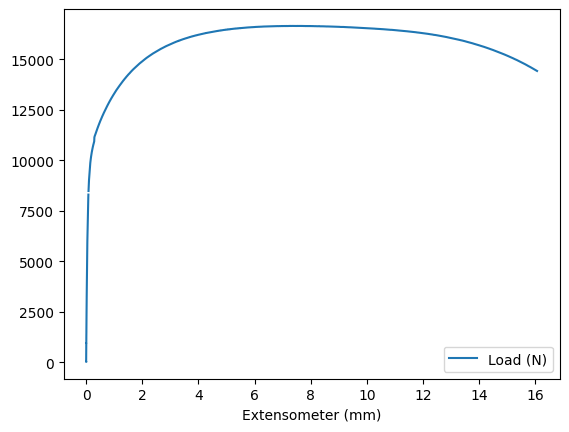

In [33]:
clean_data.loc[:3500].plot("Extensometer (mm)", "Load (N)")

In [34]:
clean_data = clean_data.loc[:3500]
clean_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3442 entries, 37 to 3500
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Index              3442 non-null   int64  
 1   Load (N)           3442 non-null   float64
 2   Crosshead (mm)     3442 non-null   float64
 3   Extensometer (mm)  3429 non-null   float64
 4   Time (sec)         3442 non-null   float64
dtypes: float64(4), int64(1)
memory usage: 161.3 KB


In [35]:
# 4. Extract Specimen Metadata

In [36]:
# 5. Determine Stress, Strain

In [37]:
# 6. Plot Results